# MCP vs direct Python: saved experiment comparison

Compare the results behind `ticket_classification_evaluation.ipynb` and
`ticket_classification_evaluation_direct.ipynb`. Run all cells using the backend
Python environment. This notebook only reads saved results and CSV reports;
it makes no API calls and does not start either workflow.

The tables show run means and sample standard deviations across three retained
runs per method. Classification scores use the same reference labels.

In [7]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


ROOT = Path.cwd()
while not (ROOT / "backend/app/validation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Open this notebook within the project folder."
        )
    ROOT = ROOT.parent
BASE = ROOT / "backend/app/validation"
EXPERIMENTS = {
    "MCP": BASE / "evaluation_results",
    "Direct Python": BASE / "evaluation_results_direct",
}
METHODS = list(EXPERIMENTS)
OUTPUT_DIR = BASE / "evaluation_comparison"
sys.path.insert(0, str(ROOT / "backend"))
from app.validation.evaluation_reporting import estimate_costs  # noqa: E402

## 1. Check the experiments

The dataset, model name, labels, concurrency and number of runs must match. Collection dates, source hashes, attempt counts and any retry information are shown separately. CSV reports must be regenerated in the source notebooks when saved responses change.


In [8]:
manifests = {
    method: json.loads(
        (folder / "experiment.json").read_text(encoding="utf-8")
    )
    for method, folder in EXPERIMENTS.items()
}
reference = manifests["MCP"]["settings"]
for method, manifest in manifests.items():
    for key in ["dataset_hash", "model", "labels", "concurrency", "n_runs"]:
        assert manifest["settings"][key] == reference[key], (
            f"{method}: {key} differs between experiments."
        )
assert reference["n_runs"] == 3
TASKS = list(reference["labels"])

metric_frames, runtime_frames, context_rows = [], [], []
saved_runs = []
for method, folder in EXPERIMENTS.items():
    manifest = manifests[method]
    attempts = previous_failures = successful = 0
    for number in range(1, reference["n_runs"] + 1):
        run_name = f"run_{number:02d}"
        run_dir = folder / run_name
        saved = json.loads(
            (run_dir / "results.json").read_text(encoding="utf-8")
        )
        saved_runs.append((method, run_name, saved))
        assert saved["settings"] == manifest["settings"]
        records = list(saved["results"].values())
        previous = [a for r in records for a in r.get("previous_attempts", [])]
        attempts += len(records) + len(previous)
        previous_failures += sum(a["status"] == "failed" for a in previous)
        successful += sum(r["status"] == "success" for r in records)
        metrics = pd.read_csv(run_dir / "metrics.csv")
        runtime = pd.read_csv(run_dir / "runtime_tokens.csv")
        assert set(metrics["task"]) == set(TASKS)
        assert len(metrics) == len(TASKS) and len(runtime) == 1
        assert (metrics["run"] == run_name).all()
        assert runtime["run"].iloc[0] == run_name
        assert (
            metrics["successful"]
            == sum(r["status"] == "success" for r in records)
        ).all()
        metric_frames.append(metrics.assign(method=method))
        runtime_frames.append(runtime.assign(method=method))
    context_rows.append(
        {
            "method": method,
            "model": manifest["settings"]["model"],
            "collection_date_utc": manifest["created_at"][:10],
            "concurrency": manifest["settings"]["concurrency"],
            "retained_runs": manifest["settings"]["n_runs"],
            "original_runs": manifest.get("report_selection", {}).get(
                "original_n_runs", manifest["settings"]["n_runs"]
            ),
            "retained_successes": successful,
            "attempts_in_retained_runs": attempts,
            "previous_failed_attempts": previous_failures,
            "source_hash": manifest["settings"]["backend_source_hash"][:12],
        }
    )
metrics = pd.concat(metric_frames, ignore_index=True)
runtime = pd.concat(runtime_frames, ignore_index=True)
context = pd.DataFrame(context_rows).set_index("method")
display(context)
assert metrics["total"].eq(100).all(), (
    "Each run must retain 100 ticket attempts."
)
assert metrics["successful"].gt(0).all(), (
    "Each run needs successful predictions."
)
print("Coverage by method and run:")
display(metrics[["method", "run", "task", "successful", "coverage"]].round(3))

,model,collection_date_utc,concurrency,retained_runs,original_runs,retained_successes,attempts_in_retained_runs,previous_failed_attempts,source_hash
method,,,,,,,,,
MCP,gpt-6-luna,2026-11-10,3,3,3,300,300,0,4ab33f4ef6a0
Direct Python,gpt-6-luna,2026-11-10,3,3,3,300,301,1,4ab33f4ef6a0


Coverage by method and run:


,method,run,task,successful,coverage
0,MCP,run_01,category,100,1.0
1,MCP,run_01,sentiment,100,1.0
2,MCP,run_01,priority,100,1.0
3,MCP,run_02,category,100,1.0
4,MCP,run_02,sentiment,100,1.0
5,MCP,run_02,priority,100,1.0
6,MCP,run_03,category,100,1.0
7,MCP,run_03,sentiment,100,1.0
8,MCP,run_03,priority,100,1.0
9,Direct Python,run_01,category,100,1.0


## 2. Classification quality

Accuracy and macro-F1 use successful decisions only. Coverage and correct-over-total include all 100 attempted tickets, counting failed requests as no correct decision. The table shows run means and sample standard deviations; these are descriptive, not confidence intervals. Changes are **Direct Python minus MCP**, in percentage points. A positive change means a higher score.


coverage_pct      accuracy_pct       macro_f1_pct  \
                                mean  std         mean   std         mean   
task      method                                                            
category  Direct Python        100.0  0.0        93.67  1.15        93.03   
          MCP                  100.0  0.0        93.33  0.58        92.60   
priority  Direct Python        100.0  0.0        88.67  1.15        91.11   
          MCP                  100.0  0.0        89.00  2.65        91.39   
sentiment Direct Python        100.0  0.0       100.00  0.00       100.00   
          MCP                  100.0  0.0        99.67  0.58        99.58   

                              correct_over_total_pct        
                          std                   mean   std  
task      method                                            
category  Direct Python  1.30                  93.67  1.15  
          MCP            0.55                  93.33  0.58  
priority  Direct Python  1.00                  88.67  1.15  
          MCP            3.35                  89.00  2.65  
sentiment Direct Python  0.00                 100.00  0.00  
          MCP            0.73                  99.67  0.58

,coverage_change_pp,accuracy_change_pp,macro_f1_change_pp,correct_over_total_change_pp
task,,,,
category,0.0,0.33,0.43,0.33
priority,0.0,-0.33,-0.28,-0.33
sentiment,0.0,0.33,0.42,0.33


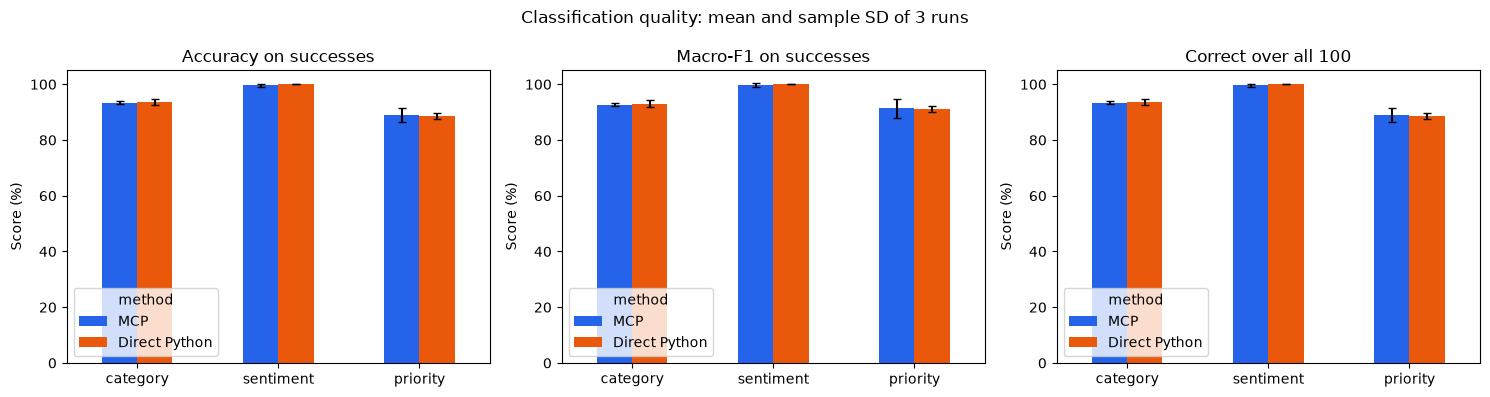

In [9]:
quality = metrics.assign(
    coverage_pct=100 * metrics["coverage"],
    accuracy_pct=100 * metrics["accuracy"],
    correct_over_total_pct=100 * metrics["correct_over_total"],
    macro_f1_pct=100 * metrics["macro_f1"],
)
score_columns = [
    "coverage_pct",
    "accuracy_pct",
    "macro_f1_pct",
    "correct_over_total_pct",
]
quality_summary = quality.groupby(["task", "method"])[score_columns].agg(
    ["mean", "std"]
)
display(quality_summary.round(2))
means = quality.groupby(["task", "method"])[score_columns].mean()
quality_difference = (
    means.xs("Direct Python", level="method") - means.xs("MCP", level="method")
).rename(
    columns={
        "coverage_pct": "coverage_change_pp",
        "accuracy_pct": "accuracy_change_pp",
        "correct_over_total_pct": "correct_over_total_change_pp",
        "macro_f1_pct": "macro_f1_change_pp",
    }
)
display(quality_difference.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(
    axes,
    ["accuracy_pct", "macro_f1_pct", "correct_over_total_pct"],
    ["Accuracy on successes", "Macro-F1 on successes", "Correct over all 100"],
):
    avg = (
        quality.groupby(["task", "method"])[column]
        .mean()
        .unstack()
        .reindex(TASKS)[METHODS]
    )
    sd = (
        quality.groupby(["task", "method"])[column]
        .std()
        .unstack()
        .reindex(TASKS)[METHODS]
    )
    avg.plot.bar(
        ax=ax, yerr=sd, capsize=3, rot=0, color=["#2563eb", "#ea580c"]
    )
    ax.set(title=title, ylabel="Score (%)", xlabel="", ylim=(0, 105))
fig.suptitle("Classification quality: mean and sample SD of 3 runs")
fig.tight_layout()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "classification_comparison.png", dpi=200)
fig.savefig(OUTPUT_DIR / "classification_comparison.pdf")
plt.show()
plt.close(fig)

## 3. Runtime and token usage

Latency describes each ticket's final attempt; earlier attempts are listed separately in the experiment context. Token means include only successful responses that returned usage; the table shows how many tickets lack usage. Run wall time includes upload and checkpointing.

Run numbers identify repetitions within each experiment, not matched requests. The comparison uses method averages rather than pairing run numbers. Negative percentage changes mean less elapsed time or fewer tokens.


Latency per attempt (s)       Tickets with token usage       \
                                 mean   std                     mean  std   
method                                                                      
Direct Python                   15.56  0.55                    100.0  0.0   
MCP                             17.62  2.02                    100.0  0.0   

              Tickets without token usage      Run wall time (s)         \
                                     mean  std              mean    std   
method                                                                    
Direct Python                         0.0  0.0            531.81   8.11   
MCP                                   0.0  0.0            594.27  71.25   

              Input tokens per ticket        Output tokens per ticket         \
                                 mean    std                     mean    std   
method                                                                         
Direct Python                 9045.98  41.39                  1056.39   6.57   
MCP                           9033.52  35.38                  1049.94  13.08   

              Total tokens per ticket         
                                 mean    std  
method                                        
Direct Python                10102.37  43.69  
MCP                          10083.46  48.43

,method,run,successful,failed,usage_missing_tickets,latency_mean_seconds,run_wall_seconds,mean_total_tokens_where_available
0,MCP,run_01,100,0,0,16.28,545.18,10122.33
1,MCP,run_02,100,0,0,16.64,561.64,10098.85
2,MCP,run_03,100,0,0,19.94,675.99,10029.20
3,Direct Python,run_01,100,0,0,15.65,527.75,10060.48
4,Direct Python,run_02,100,0,0,16.06,541.15,10147.66
5,Direct Python,run_03,100,0,0,14.97,526.55,10098.97


,MCP,Direct Python,direct_minus_mcp,change_percent
Latency per attempt (s),17.62,15.56,-2.06,-11.68
Tickets with token usage,100.00,100.00,0.00,0.00
Tickets without token usage,0.00,0.00,0.00,NaN
Run wall time (s),594.27,531.81,-62.46,-10.51
Input tokens per ticket,9033.52,9045.98,12.46,0.14
Output tokens per ticket,1049.94,1056.39,6.45,0.61
Total tokens per ticket,10083.46,10102.37,18.91,0.19


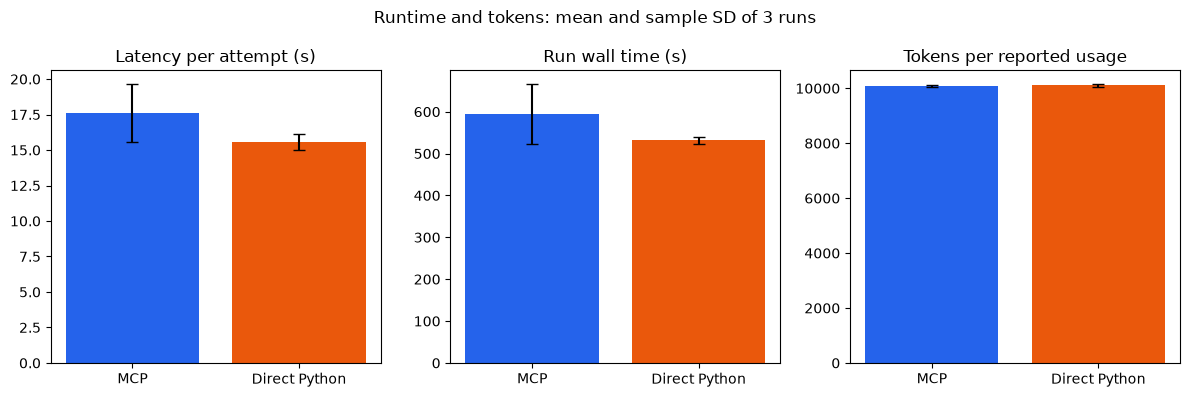

In [10]:
runtime_columns = {
    "latency_mean_seconds": "Latency per attempt (s)",
    "usage_available_tickets": "Tickets with token usage",
    "usage_missing_tickets": "Tickets without token usage",
    "run_wall_seconds": "Run wall time (s)",
    "mean_input_tokens_where_available": "Input tokens per ticket",
    "mean_output_tokens_where_available": "Output tokens per ticket",
    "mean_total_tokens_where_available": "Total tokens per ticket",
}
assert runtime["wall_time_complete"].eq(True).all(), (
    "Run wall time is incomplete."
)
runtime_summary = runtime.groupby("method")[list(runtime_columns)].agg(
    ["mean", "std"]
)
runtime_summary = runtime_summary.rename(columns=runtime_columns, level=0)
display(runtime_summary.round(2))
display(
    runtime[
        [
            "method",
            "run",
            "successful",
            "failed",
            "usage_missing_tickets",
            "latency_mean_seconds",
            "run_wall_seconds",
            "mean_total_tokens_where_available",
        ]
    ].round(2)
)

averages = runtime.groupby("method")[list(runtime_columns)].mean()
runtime_difference = pd.DataFrame(
    {
        "MCP": averages.loc["MCP"],
        "Direct Python": averages.loc["Direct Python"],
    }
)
runtime_difference["direct_minus_mcp"] = (
    runtime_difference["Direct Python"] - runtime_difference["MCP"]
)
runtime_difference["change_percent"] = (
    100 * runtime_difference["direct_minus_mcp"] / runtime_difference["MCP"]
)
runtime_difference = runtime_difference.rename(index=runtime_columns)
display(runtime_difference.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, column, title in zip(
    axes,
    [
        "latency_mean_seconds",
        "run_wall_seconds",
        "mean_total_tokens_where_available",
    ],
    [
        "Latency per attempt (s)",
        "Run wall time (s)",
        "Tokens per reported usage",
    ],
):
    grouped = runtime.groupby("method")[column]
    avg, sd = grouped.mean().reindex(METHODS), grouped.std().reindex(METHODS)
    ax.bar(METHODS, avg, yerr=sd, capsize=4, color=["#2563eb", "#ea580c"])
    ax.set(title=title, ylim=(0, None))
fig.suptitle("Runtime and tokens: mean and sample SD of 3 runs")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "runtime_comparison.png", dpi=200)
fig.savefig(OUTPUT_DIR / "runtime_comparison.pdf")
plt.show()
plt.close(fig)

## 4. Interpretation and saved tables

These are descriptive comparisons of three fresh runs per method on the same revised dataset. Both methods use the same backend and configured model, and execute sequentially with concurrency three. All attempts, including failures, are retained without automatic retries or run selection.

Coverage and correct-over-total account for failed requests. Accuracy and macro-F1 describe successful decisions; if coverage differs, compare those scores with caution. Model variation, caching, collection order and provider load can affect measurements. Latency differences cannot be attributed solely to MCP overhead. Three runs provide no significance test or causal claim.

Exports are written to `evaluation_comparison/`; the source experiments are only read.


In [11]:
context.to_csv(OUTPUT_DIR / "experiment_context.csv")
metrics.to_csv(OUTPUT_DIR / "metrics_by_run.csv", index=False)
runtime.to_csv(OUTPUT_DIR / "runtime_by_run.csv", index=False)
quality_summary.to_csv(OUTPUT_DIR / "classification_summary.csv")
quality_difference.to_csv(OUTPUT_DIR / "classification_difference.csv")
runtime_summary.to_csv(OUTPUT_DIR / "runtime_summary.csv")
runtime_difference.to_csv(OUTPUT_DIR / "runtime_difference.csv")
print("Saved comparison tables and charts to:", OUTPUT_DIR)

Saved comparison tables and charts to: c:\Users\lenovo\Documents\thesis\backend\app\validation\evaluation_comparison


## 5. Estimated API cost

[Standard OpenAI rates](https://developers.openai.com/api/docs/pricing), checked
2026-11-11: **$0.10/M input tokens** and **$0.50/M output tokens** for `gpt-6-luna`.
Estimates use uncached rates and recorded usage; missing usage, cache adjustments,
surcharges, taxes and hosting are excluded.


In [12]:
cost_by_run, cost_summary = estimate_costs(runtime, reference["model"])
display(cost_by_run.round(6), cost_summary.round(6))
cost_by_run.to_csv(OUTPUT_DIR / "cost_by_run.csv", index=False)
cost_summary.to_csv(OUTPUT_DIR / "cost_summary.csv")

cost_difference = cost_summary[
    ["mean_run_cost_usd", "mean_ticket_cost_usd"]
].T.reindex(columns=METHODS)
cost_difference["direct_minus_mcp_usd"] = (
    cost_difference["Direct Python"] - cost_difference["MCP"]
)
cost_difference["change_percent"] = (
    100
    * cost_difference["direct_minus_mcp_usd"]
    / cost_difference["MCP"].replace(0, float("nan"))
)
display(cost_difference.round(6))
cost_difference.to_csv(OUTPUT_DIR / "cost_difference.csv")

,method,run,usage_available_tickets,usage_missing_tickets,observed_input_tokens,observed_output_tokens,pricing_model,pricing_date,input_usd_per_million,output_usd_per_million,estimated_input_cost_usd,estimated_output_cost_usd,estimated_total_cost_usd,mean_ticket_cost_usd
0,MCP,run_01,100,0,906126,106107,gpt-6-luna,2026-11-11,0.1,0.5,0.090613,0.053054,0.143666,0.001437
1,MCP,run_02,100,0,904563,105322,gpt-6-luna,2026-11-11,0.1,0.5,0.090456,0.052661,0.143117,0.001431
2,MCP,run_03,100,0,899367,103553,gpt-6-luna,2026-11-11,0.1,0.5,0.089937,0.051776,0.141713,0.001417
3,Direct Python,run_01,100,0,901055,104993,gpt-6-luna,2026-11-11,0.1,0.5,0.090106,0.052496,0.142602,0.001426
4,Direct Python,run_02,100,0,909148,105618,gpt-6-luna,2026-11-11,0.1,0.5,0.090915,0.052809,0.143724,0.001437
5,Direct Python,run_03,100,0,903591,106306,gpt-6-luna,2026-11-11,0.1,0.5,0.090359,0.053153,0.143512,0.001435


,runs,tickets_with_usage,tickets_without_usage,estimated_total_cost_usd,mean_run_cost_usd,std_run_cost_usd,mean_ticket_cost_usd
method,,,,,,,
Direct Python,3,300,0,0.429838,0.143279,0.000596,0.001433
MCP,3,300,0,0.428497,0.142832,0.001007,0.001428


method,MCP,Direct Python,direct_minus_mcp_usd,change_percent
mean_run_cost_usd,0.142832,0.143279,0.000447,0.313025
mean_ticket_cost_usd,0.001428,0.001433,0.000004,0.313025


## 6. Call counts

Resource reads and saving operations are recorded for successful final attempts;
model/API request counts were not saved.
One model response can request several operations, so these counts cannot tell
us how many API requests were made.


In [16]:
call_rows = []
for method, run_name, saved in saved_runs:
    responses = [
        record["response"]
        for record in saved["results"].values()
        if record["status"] == "success"
    ]
    call_rows.append(
        {
            "method": method,
            "run": run_name,
            "successful_tickets": len(responses),
            "resource_reads": sum(
                len(r["mcpResourceReads"]) for r in responses
            ),
            "saving_operations": sum(
                len(r["mcpToolResults"]) for r in responses
            ),
        }
    )
call_counts_by_run = pd.DataFrame(call_rows)
call_counts = call_counts_by_run.groupby("method")[
    ["successful_tickets", "resource_reads", "saving_operations"]
].sum()
call_counts["reads_per_ticket"] = (
    call_counts["resource_reads"] / call_counts["successful_tickets"]
)
call_counts["saves_per_ticket"] = (
    call_counts["saving_operations"] / call_counts["successful_tickets"]
)

display(call_counts_by_run)
display(call_counts.round(3))
call_counts_by_run.to_csv(OUTPUT_DIR / "call_counts_by_run.csv", index=False)
call_counts.to_csv(OUTPUT_DIR / "call_count_summary.csv")

,method,run,successful_tickets,resource_reads,saving_operations
0,MCP,run_01,100,102,400
1,MCP,run_02,100,102,400
2,MCP,run_03,100,101,400
3,Direct Python,run_01,100,101,400
4,Direct Python,run_02,100,103,400
5,Direct Python,run_03,100,101,400


,successful_tickets,resource_reads,saving_operations,reads_per_ticket,saves_per_ticket
method,,,,,
Direct Python,300,305,1200,1.017,4.0
MCP,300,305,1200,1.017,4.0


## 7. Timing by component

Only total HTTP latency was recorded; the component times below were not saved.
The difference between methods is not a measured MCP startup or transport time.

Mean latency covers a complete `/analyze` request, including model rounds and local processing.


In [19]:
components = [
    "Mean end-to-end analysis latency (s)",
]
component_timing = pd.DataFrame(
    float("nan"), index=components, columns=METHODS
)
component_timing.index.name = "component"
component_timing.loc["Mean end-to-end analysis latency (s)"] = (
    runtime.groupby("method")["latency_mean_seconds"].mean().reindex(METHODS)
)
display(component_timing.round(3))
component_timing.to_csv(OUTPUT_DIR / "component_timing.csv")

,MCP,Direct Python
component,,
Mean end-to-end analysis latency (s),17.617,15.558
